Tugas Mechine Learning 11

11.1 Persiapan Library

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

11.2 Import Dataset

In [10]:
digits = load_digits()
X, y =  digits.data, digits.target
print("Dimensi data asli:", X.shape) # (1797, 64)

Dimensi data asli: (1797, 64)


11.3 Preprocessing

In [11]:
X_scaled = StandardScaler().fit_transform(X)

11.4 Training Model (PCA, t-SNE, LDA)

In [12]:
pca = PCA(n_components=0.90)
X_pca = pca.fit_transform(X_scaled)
print("Jumlah komponen untuk 90% variance:", pca.n_components_)

X_tsne = TSNE(n_components=2,perplexity=30,random_state=42).fit_transform(X_scaled)

lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X_scaled, y) # LDA memerlukan label y

Jumlah komponen untuk 90% variance: 31


11.5 Evaluasi

In [13]:
print("Explained variance ratio (5 komponen pertama):",
      np.round(pca.explained_variance_ratio_[:5], 3))
print("Total variance dijelaskan:",
      round(pca.explained_variance_ratio_.sum(), 3))

Explained variance ratio (5 komponen pertama): [0.12  0.096 0.084 0.065 0.049]
Total variance dijelaskan: 0.9


11.6 Visualisasi

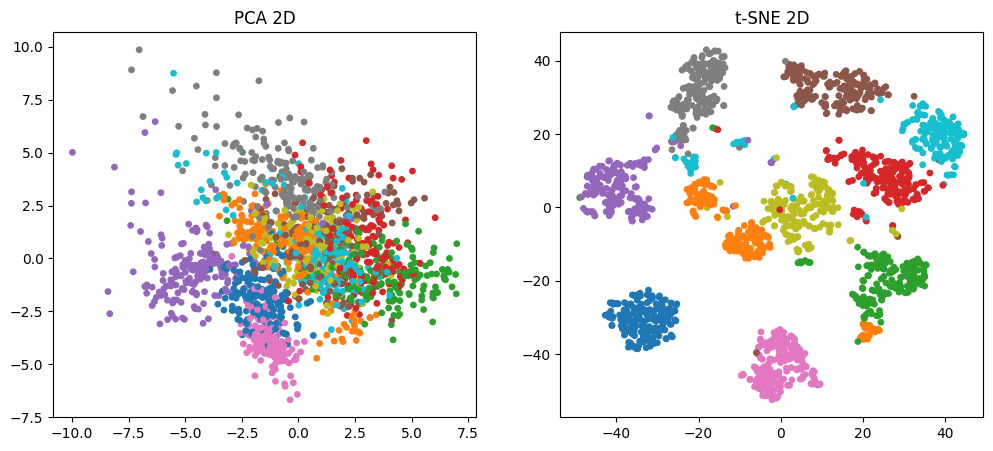

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))
axes[0].scatter(X_pca[:,0], X_pca[:,1], c=y,cmap="tab10",s=15)
axes[0].set_title("PCA 2D")
axes[1].scatter(X_tsne[:,0], X_tsne[:,1], c=y,cmap="tab10",s=15)
axes[1].set_title("t-SNE 2D")
plt.show()

11.7

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

for n_comp in [0.80, 0.90, 0.95, None]:
  pca = PCA(n_components=n_comp)
  X_train_p = pca.fit_transform(X_train)
  X_test_p = pca.transform(X_test)
  model = LogisticRegression(max_iter=2000).fit(X_train_p, y_train)

  acc = accuracy_score(y_test, model.predict(X_test_p))
  print(f"n_components={n_comp}: dimensi={X_train_p.shape[1]}, akurasi={acc:.3f}")

n_components=0.8: dimensi=21, akurasi=0.947
n_components=0.9: dimensi=31, akurasi=0.958
n_components=0.95: dimensi=40, akurasi=0.964
n_components=None: dimensi=64, akurasi=0.972


## Praktikum 2: Perbandingan PCA, t-SNE, dan LDA

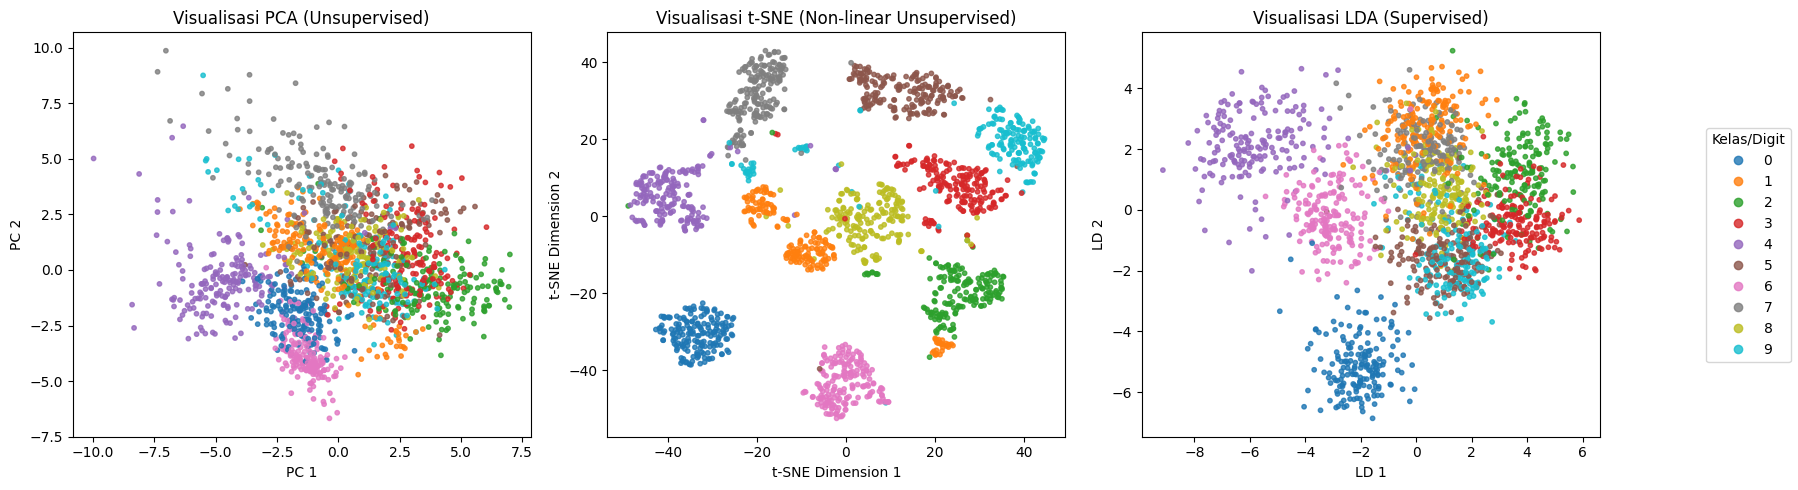

In [18]:
import matplotlib.pyplot as plt

# 1. PCA ke 2 dimensi
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

# 2. t-SNE ke 2 dimensi
# X_tsne sudah dijalankan di cell sebelumnya, kita bisa langsung menggunakannya atau mendefinisikannya kembali jika perlu

# 3. LDA ke 2 dimensi
# X_lda juga sudah didefinisikan di sel sebelumnya menggunakan LinearDiscriminantAnalysis(n_components=2)

# Plotting berdampingan
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot PCA
scatter1 = axes[0].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y, cmap="tab10", s=10, alpha=0.8)
axes[0].set_title("Visualisasi PCA (Unsupervised)")
axes[0].set_xlabel("PC 1")
axes[0].set_ylabel("PC 2")

# Subplot t-SNE
scatter2 = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap="tab10", s=10, alpha=0.8)
axes[1].set_title("Visualisasi t-SNE (Non-linear Unsupervised)")
axes[1].set_xlabel("t-SNE Dimension 1")
axes[1].set_ylabel("t-SNE Dimension 2")

# Subplot LDA
scatter3 = axes[2].scatter(X_lda[:, 0], X_lda[:, 1], c=y, cmap="tab10", s=10, alpha=0.8)
axes[2].set_title("Visualisasi LDA (Supervised)")
axes[2].set_xlabel("LD 1")
axes[2].set_ylabel("LD 2")

# Menambahkan legend global
handles, labels = scatter1.legend_elements()
fig.legend(handles, labels, loc='center right', title="Kelas/Digit")
fig.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()

### Analisis Kualitas Pemisahan Kelas:

1. **PCA (Principal Component Analysis)**:
   * **Karakteristik**: Metode linear dan bersifat *unsupervised*.
   * **Kualitas Pemisahan**: Pemisahan kelas pada proyeksi 2D PCA kurang optimal. Banyak kelas (angka) yang saling tumpang tindih (*overlap*) di bagian tengah plot. Hal ini dikarenakan PCA hanya berfokus pada mempertahankan variansi global data terbesar, bukan untuk memisahkan kelas.

2. **t-SNE (t-Distributed Stochastic Neighbor Embedding)**:
   * **Karakteristik**: Metode non-linear berbasis manifold dan bersifat *unsupervised*.
   * **Kualitas Pemisahan**: Sangat baik. t-SNE berhasil mengelompokkan data ke dalam kluster-kluster yang sangat terpisah secara jelas berdasarkan kemiripan lokalnya. Meskipun tanpa informasi label kelas saat fitting, t-SNE mampu membentuk struktur spasial yang mengenali pola angka dengan sangat baik.

3. **LDA (Linear Discriminant Analysis)**:
   * **Karakteristik**: Metode linear dan bersifat *supervised* (menggunakan informasi label kelas `y`).
   * **Kualitas Pemisahan**: Sangat terstruktur dan jauh lebih baik daripada PCA linear. Karena LDA memaksimalkan rasio variansi antar-kelas dengan variansi di dalam-kelas, hasil proyeksi 2 dimensi menunjukkan pemisahan kelompok kelas yang cukup baik, meskipun beberapa kelas masih memiliki sedikit batas yang berhimpitan dibandingkan visualisasi t-SNE.